In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Using: cuda


In [3]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Loaded from:", torch.__file__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

Python: /home/abhi/miniconda3/envs/ml-assignment/bin/python
PyTorch: 2.14.1+cu130
Loaded from: /home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/torch/__init__.py
CUDA build: 13.0
CUDA available: True


In [4]:
# Activation functions and their gradients
def sigmoid(x):
    return torch.sigmoid(x)

def sigmoid_gradient(x):
    output = sigmoid(x)
    return output * (1 - output)

def tanh(x):
    return torch.tanh(x)

def tanh_gradient(x):
    output = tanh(x)
    return 1 - output.square()

def relu(x):
    return torch.relu(x)

def relu_gradient(x):
    return (x > 0).to(dtype=x.dtype)

def leaky_relu(x, alpha=0.01):
    return torch.where(x > 0, x, alpha * x)

def leaky_relu_gradient(x, alpha=0.01):
    return torch.where(x > 0, torch.ones_like(x), torch.full_like(x, alpha))

def linear(x):
    return x

def linear_gradient(x):
    return torch.ones_like(x)

def softmax(x):
    return torch.softmax(x, dim=-1)

# Weight initialization functions
def zero_init(shape):
    return np.zeros(shape)
def random_init(shape):
    return np.random.rand(*shape)-0.5
def normal_init(shape):
    return np.random.normal(0, 1, shape)


In [6]:
class NeuralNetwork:
    def __init__(self, N, layer_sizes, lr, activation, weight_init, num_epochs, batch_size,der_activation):
        self.Noflayers = N
        self.Ninlayer = layer_sizes
        self.lr = lr
        self.activation = activation
        self.weight_init = weight_init
        self.num_epochs = num_epochs
        self.batch_size = batch_size
        self.weights = []
        self.biases = []
        self.der_activation=der_activation
        for i in range(self.Noflayers-1):
            in_size = self.Ninlayer[i]
            out_size = self.Ninlayer[i + 1]
            W = self.weight_init((in_size, out_size))
            b = np.zeros((1, out_size))
            self.weights.append(torch.tensor(W, dtype=torch.float32, device=device,))
            self.biases.append(torch.tensor(b, dtype=torch.float32, device=device,))
    def forward(self, X):
        a=X
        self.activations=[a]
        self.z_values=[]

        for i, (W, b) in enumerate(zip(self.weights, self.biases)):
            z=a@W+b
            self.z_values.append(z)
            if i==len(self.weights) - 1:
                a=torch.softmax(z, dim=1)             # output layer
            else:
                a=self.activation(z)     # hidden layers
            self.activations.append(a)

        return a

    def one_hot(self, Y):
        Y = torch.as_tensor(Y, dtype=torch.long, device=device).reshape(-1)
        num_classes = self.Ninlayer[-1]

        one_hot_Y = torch.zeros(
            (Y.shape[0], num_classes),
            dtype=torch.float32,
            device=device
        )
        one_hot_Y[torch.arange(Y.shape[0], device=device), Y] = 1.0
        return one_hot_Y

    def backward(self, Y_one_hot):
        """
        Y_one_hot: shape (batch_size, number_of_classes)
        Assumes forward(X) has already been called for this batch.
        """
        m = Y_one_hot.shape[0]
        num_layers = len(self.weights)

        last_values=self.z_values[-1]
        log_probs=torch.log_softmax(last_values, dim=1)
        cross_entropy_loss=-(Y_one_hot * log_probs).sum(dim=1).mean()

        # Softmax + cross-entropy output gradient
        delta=(self.activations[-1]-Y_one_hot)/m

        # dW = [torch.zeros_like(self.weights[i]) for i in range(num_layers)]
        # db = [torch.zeros_like(self.biases[i]) for i in range(num_layers)]
        dW=[None]*num_layers
        db=[None]*num_layers

        for i in range(num_layers-1, -1, -1):
            dW[i]=self.activations[i].T @ delta
            db[i]=delta.sum(dim=0, keepdim=True)
            if i > 0:
                delta=(delta @ self.weights[i].T)*self.der_activation(self.z_values[i-1])

        with torch.no_grad():
            for i in range(num_layers):
                self.weights[i] -= self.lr * dW[i]
                self.biases[i] -= self.lr * db[i]

        return cross_entropy_loss.item()

    def fit(self, X, Y, X_valid=None, Y_valid=None):
        X = torch.as_tensor(X, dtype=torch.float32, device=device)
        Y = torch.as_tensor(Y, dtype=torch.long, device=device).reshape(-1)

        if X_valid is not None and Y_valid is not None:
            X_valid = torch.as_tensor(
                X_valid, dtype=torch.float32, device=device
            )
            Y_valid = torch.as_tensor(
                Y_valid, dtype=torch.long, device=device
            ).reshape(-1)
            Y_valid_one_hot = self.one_hot(Y_valid)

        Y_one_hot = self.one_hot(Y)
        n = X.shape[0]

        train_losses = []
        valid_losses = []

        for epoch in range(self.num_epochs):
            total_train_loss = 0.0
            for start in range(0, n, self.batch_size):
                end = min(start + self.batch_size, n)
                X_batch = X[start:end]
                Y_batch = Y_one_hot[start:end]

                self.forward(X_batch)
                batch_loss = self.backward(Y_batch)
                total_train_loss += batch_loss * (end - start)

            epoch_train_loss=total_train_loss/n
            train_losses.append(epoch_train_loss)

            if X_valid is not None and Y_valid is not None:
                with torch.no_grad():
                    self.forward(X_valid)
                    valid_logits = self.z_values[-1]
                    valid_loss = -(Y_valid_one_hot*torch.log_softmax(valid_logits, dim=1)).sum(dim=1).mean().item()

                valid_losses.append(valid_loss)
                print(
                    f"Epoch {epoch + 1}/{self.num_epochs}, "
                    f"Train Loss: {epoch_train_loss:.4f}, "
                    f"Validation Loss: {valid_loss:.4f}"
                )
            else:
                print(
                    f"Epoch {epoch + 1}/{self.num_epochs}, "
                    f"Train Loss: {epoch_train_loss:.4f}"
                )

        # Plot the loss history
        epochs = range(1, self.num_epochs + 1)
        plt.plot(epochs, train_losses, label="Training Loss")

        if X_valid is not None and Y_valid is not None:
            plt.plot(epochs, valid_losses, label="Validation Loss")

        plt.xlabel("Epoch")
        plt.ylabel("Cross-entropy loss")
        plt.legend()
        plt.show()

        return train_losses, valid_losses
    
    def predict_proba(self, X):
        scores = self.forward(X)
        return scores

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return np.argmax(probabilities, 0)

    def score(self, X, Y):
        predictions = self.predict(X)
        accuracy = np.sum(predictions == Y) / Y.size
        return accuracy

Training model with sigmoid activation function...
Epoch 1/100, Train Loss: 2.3180, Validation Loss: 2.2754
Epoch 2/100, Train Loss: 2.2564, Validation Loss: 2.2341
Epoch 3/100, Train Loss: 2.2102, Validation Loss: 2.1810
Epoch 4/100, Train Loss: 2.1481, Validation Loss: 2.1076
Epoch 5/100, Train Loss: 2.0611, Validation Loss: 2.0059
Epoch 6/100, Train Loss: 1.9451, Validation Loss: 1.8772
Epoch 7/100, Train Loss: 1.8081, Validation Loss: 1.7361
Epoch 8/100, Train Loss: 1.6676, Validation Loss: 1.5999
Epoch 9/100, Train Loss: 1.5372, Validation Loss: 1.4778
Epoch 10/100, Train Loss: 1.4226, Validation Loss: 1.3720
Epoch 11/100, Train Loss: 1.3236, Validation Loss: 1.2807
Epoch 12/100, Train Loss: 1.2379, Validation Loss: 1.2012
Epoch 13/100, Train Loss: 1.1626, Validation Loss: 1.1309
Epoch 14/100, Train Loss: 1.0955, Validation Loss: 1.0677
Epoch 15/100, Train Loss: 1.0347, Validation Loss: 1.0099
Epoch 16/100, Train Loss: 0.9788, Validation Loss: 0.9565
Epoch 17/100, Train Loss: 0.92

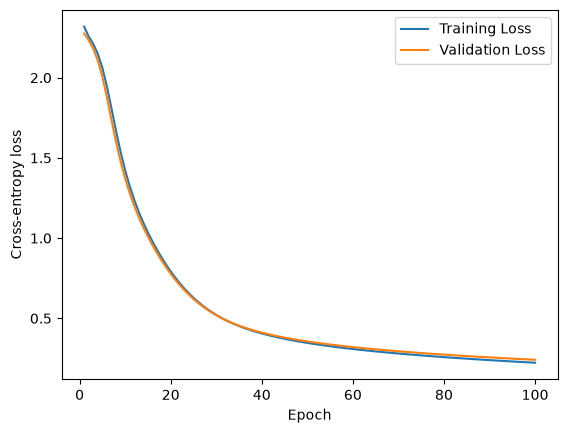

Test Accuracy (sigmoid): 0.9343
Training model with tanh activation function...
Epoch 1/100, Train Loss: 1.8236, Validation Loss: 1.2185
Epoch 2/100, Train Loss: 1.0186, Validation Loss: 0.8972
Epoch 3/100, Train Loss: 0.7913, Validation Loss: 0.7568
Epoch 4/100, Train Loss: 0.6729, Validation Loss: 0.6718
Epoch 5/100, Train Loss: 0.5964, Validation Loss: 0.6132
Epoch 6/100, Train Loss: 0.5413, Validation Loss: 0.5695
Epoch 7/100, Train Loss: 0.4988, Validation Loss: 0.5352
Epoch 8/100, Train Loss: 0.4647, Validation Loss: 0.5075
Epoch 9/100, Train Loss: 0.4364, Validation Loss: 0.4848
Epoch 10/100, Train Loss: 0.4123, Validation Loss: 0.4659
Epoch 11/100, Train Loss: 0.3914, Validation Loss: 0.4499
Epoch 12/100, Train Loss: 0.3729, Validation Loss: 0.4363
Epoch 13/100, Train Loss: 0.3565, Validation Loss: 0.4246
Epoch 14/100, Train Loss: 0.3417, Validation Loss: 0.4144
Epoch 15/100, Train Loss: 0.3282, Validation Loss: 0.4054
Epoch 16/100, Train Loss: 0.3159, Validation Loss: 0.3974
E

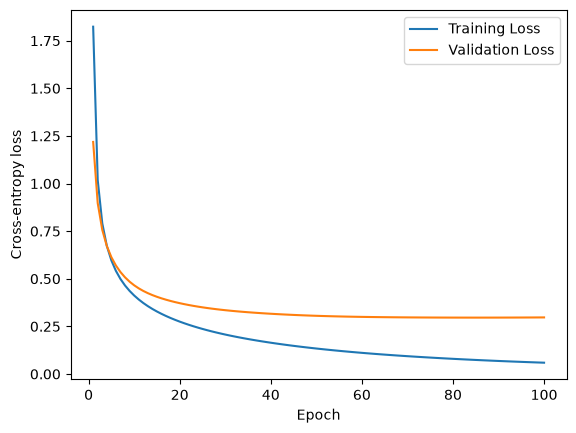

Test Accuracy (tanh): 0.9302
Training model with relu activation function...
Epoch 1/100, Train Loss: 2.2648, Validation Loss: 1.8488
Epoch 2/100, Train Loss: 1.5728, Validation Loss: 1.2134
Epoch 3/100, Train Loss: 0.9887, Validation Loss: 0.8238
Epoch 4/100, Train Loss: 0.7134, Validation Loss: 0.6541
Epoch 5/100, Train Loss: 0.5655, Validation Loss: 0.5493
Epoch 6/100, Train Loss: 0.4807, Validation Loss: 0.4817
Epoch 7/100, Train Loss: 0.4275, Validation Loss: 0.4397
Epoch 8/100, Train Loss: 0.3884, Validation Loss: 0.4081
Epoch 9/100, Train Loss: 0.3592, Validation Loss: 0.3840
Epoch 10/100, Train Loss: 0.3364, Validation Loss: 0.3658
Epoch 11/100, Train Loss: 0.3178, Validation Loss: 0.3507
Epoch 12/100, Train Loss: 0.3018, Validation Loss: 0.3374
Epoch 13/100, Train Loss: 0.2883, Validation Loss: 0.3264
Epoch 14/100, Train Loss: 0.2766, Validation Loss: 0.3167
Epoch 15/100, Train Loss: 0.2659, Validation Loss: 0.3079
Epoch 16/100, Train Loss: 0.2565, Validation Loss: 0.3002
Epoc

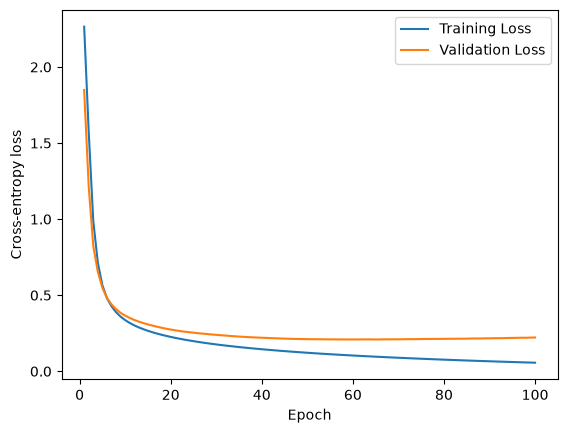

Test Accuracy (relu): 0.9519
Training model with leaky_relu activation function...
Epoch 1/100, Train Loss: 1.9829, Validation Loss: 1.2258
Epoch 2/100, Train Loss: 1.0154, Validation Loss: 0.8567
Epoch 3/100, Train Loss: 0.7302, Validation Loss: 0.6778
Epoch 4/100, Train Loss: 0.5844, Validation Loss: 0.5750
Epoch 5/100, Train Loss: 0.5024, Validation Loss: 0.5166
Epoch 6/100, Train Loss: 0.4493, Validation Loss: 0.4685
Epoch 7/100, Train Loss: 0.4104, Validation Loss: 0.4328
Epoch 8/100, Train Loss: 0.3801, Validation Loss: 0.4014
Epoch 9/100, Train Loss: 0.3560, Validation Loss: 0.3810
Epoch 10/100, Train Loss: 0.3363, Validation Loss: 0.3620
Epoch 11/100, Train Loss: 0.3190, Validation Loss: 0.3461
Epoch 12/100, Train Loss: 0.3044, Validation Loss: 0.3333
Epoch 13/100, Train Loss: 0.2914, Validation Loss: 0.3223
Epoch 14/100, Train Loss: 0.2800, Validation Loss: 0.3119
Epoch 15/100, Train Loss: 0.2697, Validation Loss: 0.3029
Epoch 16/100, Train Loss: 0.2604, Validation Loss: 0.295

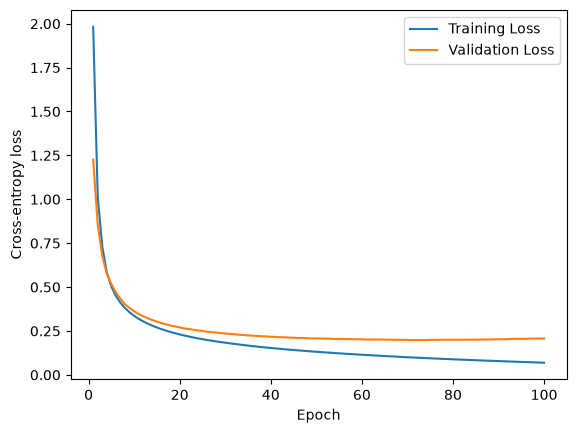

Test Accuracy (leaky_relu): 0.9543


In [7]:
# Compare activation functions on MNIST using the allowed random initializer.
from torchvision.datasets import MNIST

mnist_train = MNIST(root="./data", train=True, download=True)
mnist_test = MNIST(root="./data", train=False, download=True)

# Flatten images and scale pixel values to [0, 1].
X_all = mnist_train.data.reshape(-1, 28 * 28).float() / 255.0
Y_all = mnist_train.targets.long()
X_test = mnist_test.data.reshape(-1, 28 * 28).float().to(device) / 255.0
Y_test = mnist_test.targets.long().to(device)

# Split training data into training and validation sets (55,000 / 5,000).
generator = torch.Generator().manual_seed(2025)
indices = torch.randperm(len(X_all), generator=generator)
train_indices = indices[:55000]
valid_indices = indices[55000:]
X_train = X_all[train_indices].to(device)
Y_train = Y_all[train_indices].to(device)
X_valid = X_all[valid_indices].to(device)
Y_valid = Y_all[valid_indices].to(device)

activations = {
    "sigmoid": (sigmoid, sigmoid_gradient),
    "tanh": (tanh, tanh_gradient),
    "relu": (relu, relu_gradient),
    "leaky_relu": (leaky_relu, leaky_relu_gradient),
}

layer_sizes = [784, 256, 128, 64, 32, 10]
num_epochs = 100

for name, (activation_fn, gradient_fn) in activations.items():
    # Reset the seed so each activation starts with the same random weights.
    np.random.seed(2025)
    model = NeuralNetwork(
        N=len(layer_sizes),
        layer_sizes=layer_sizes,
        lr=0.01,
        activation=activation_fn,
        weight_init=random_init,
        num_epochs=num_epochs,
        batch_size=128,
        der_activation=gradient_fn,
    )

    print(f"Training model with {name} activation function...")
    model.fit(X_train, Y_train, X_valid=X_valid, Y_valid=Y_valid)

    with torch.no_grad():
        predictions = torch.argmax(model.forward(X_test), dim=1)
        test_accuracy = (predictions == Y_test).float().mean().item()

    print(f"Test Accuracy ({name}): {test_accuracy:.4f}")
